# Demo 3 · Reading a digit with scikit-learn

Can we recognize a digit with only **16 pixels**? And be wrong with confidence?

In this lab, you will compare a classifier to a baseline, choose its settings with cross-validation, and interpret its errors.

Complete the **five exercises in order**; their solutions are folded just below each one. "Run all" works once the exercises are completed.

If a variable is missing (`NameError`), check that the cell that creates it has been run. After a change, rerun that cell and the ones after it.

Reminders point to the [course site](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a) and to the slide numbers **shown on the slides**, not to the PDF pages.


## Getting started in Google Colab

Upload this file to [Google Colab](https://colab.research.google.com/) and keep the standard runtime **on CPU, without a GPU**. No Drive mount is needed.

1. Set `INSTALL_COLAB_PACKAGES = True` and run the installation cell.
2. The message asking for a restart is expected: restart the session, then set this option back to `False`.
3. Rerun the installation cell, then the imports: the versions are displayed. Continue in order and complete the five exercises.

The installation requires Internet access. The data ships with scikit-learn. If the widgets do not display, set `SHOW_WIDGETS = False` and rerun the configuration cell: every comparison also has a static figure.

**Locally, if needed:** at the root of the repository, run `uv sync`, then `uv run jupyter lab`. Choose the kernel from the shared `.venv`.


In [ ]:
# Install only the required dependencies in Colab, then restart.
INSTALL_COLAB_PACKAGES = False
SHOW_WIDGETS = True

import sys
import subprocess

try:
    from google.colab import output
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and INSTALL_COLAB_PACKAGES:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "uv>=0.8,<1"])
    subprocess.check_call([
        sys.executable, "-m", "uv", "pip", "install", "--python", sys.executable,
        "scikit-learn==1.9.1", "numpy>=1.26,<3",
        "matplotlib>=3.9,<4", "ipywidgets>=8.1,<9",
    ])
    raise SystemExit("Redémarrer la session et remettre INSTALL_COLAB_PACKAGES = False.")

if IN_COLAB and SHOW_WIDGETS:
    output.enable_custom_widget_manager()


In [ ]:
# Import the tools; fix the seed and use the same folds for every comparison.
import sklearn
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from sklearn.datasets import load_digits, make_moons
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print("Python :", sys.version.split()[0], "| scikit-learn :", sklearn.__version__, "| NumPy :", np.__version__)


Python : 3.13.15 | scikit-learn : 1.6.1 | NumPy : 2.1.3


## 1 · An image is a row of a table

An image is 8 × 8 pixels: **64 intensities**, from 0 to 16. `X` holds the features, `y` the expected digit (0–9). This small **Digits dataset is not MNIST**.

Before exploring, set aside 25% of the examples for the final test. Cross-validation will only use the remaining 75%.

**Reminder:** generalization and evaluation outside training — [lecture 3, slide 14](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a). [Digits dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).

**Question:** does one image provide one observation, eight observations, or 64 observations?


In [ ]:
# Load the images: one row of X holds the 64 pixels of one digit.
digits = load_digits()
X, y = digits.data, digits.target
print("X:", X.shape, "| y:", y.shape)
print("Intensités :", X.min(), "à", X.max())


X: (1797, 64) | y: (1797,)
Intensités : 0.0 à 16.0


In [ ]:
# EXERCISE 1/5 · Set aside the test set without changing the class proportions.
# Create X_train, X_test, y_train, y_test with train_test_split.
# Use test_size=0.25, stratify=y and random_state=SEED.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)


<details>
<summary>Solution to exercise 1 — open if needed</summary>

```python
# Split before any preprocessing; keep the distribution of digits.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
```

</details>


In [ ]:
# Show the size of both sets; the test set stays set aside.
print("Entraînement :", X_train.shape, "| Test réservé :", X_test.shape)


Entraînement : (1347, 64) | Test réservé : (450, 64)


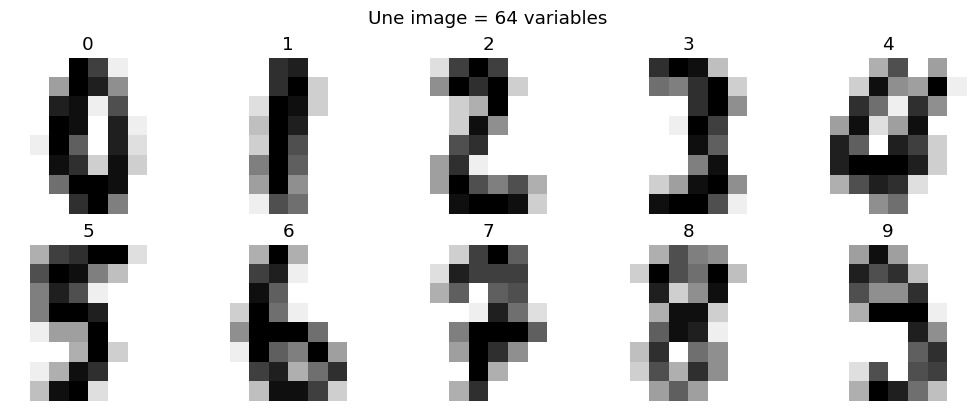

In [ ]:
# Show one example of each digit, from the training set only.
fig, axes = plt.subplots(2, 5, figsize=(10, 4), layout="constrained")
for digit, ax in enumerate(axes.flat):
    image = X_train[y_train == digit][0].reshape(8, 8)
    ax.imshow(image, cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(str(digit))
    ax.set_axis_off()
fig.suptitle("Une image = 64 variables")
plt.show()


In [ ]:
# Link an 8 × 8 image to its row of 64 features.
print("Première image d’entraînement, deux premières lignes :")
print(X_train[0].reshape(8, 8)[:2].astype(int))
print("Les mêmes 16 valeurs dans X_train[0, :16] :")
print(X_train[0, :16].astype(int))


Première image d’entraînement, deux premières lignes :
[[ 0  2 12 16 12  0  0  0]
 [ 0  7 16 13 16  3  0  0]]
Les mêmes 16 valeurs dans X_train[0, :16] :
[ 0  2 12 16 12  0  0  0  0  7 16 13 16  3  0  0]


## 2 · Before celebrating: a baseline

The baseline always predicts the most frequent digit **in the training set**. It does not use the pixels.

Cross-validation splits the training set into three folds: each example is used once for validation and twice for training. **The held-out test set never takes part.**

**Reminder:** comparing models on the same data — [lecture 3, slide 27](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a); measuring and validating — [lecture 7, slide 11](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a). [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).

**What do you think?** With ten fairly balanced classes, does the baseline reach roughly 10%, 50%, or 90%?


In [ ]:
# EXERCISE 2/5 · Train the baseline and measure its cross-validation score.
# Create baseline = DummyClassifier(strategy="most_frequent").
# Train on X_train, y_train; compute baseline_scores with cross_val_score.
# Reuse cv, scoring="accuracy" and n_jobs=1.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_scores = cross_val_score(
    baseline, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=1
)

<details>
<summary>Solution to exercise 2 — open if needed</summary>

```python
# Learn the majority class and reuse the same validation folds.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_scores = cross_val_score(
    baseline, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=1
)
```

</details>


In [ ]:
# Summarize the three scores; their standard deviation is not a confidence interval.
print("Accuracy par pli :", np.round(baseline_scores, 3))
print(f"Accuracy CV moyenne : {baseline_scores.mean():.1%}")
print(f"Écart-type entre plis : {baseline_scores.std():.1%}")


Accuracy par pli : [0.1   0.102 0.1  ]
Accuracy CV moyenne : 10.1%
Écart-type entre plis : 0.1%


## 3 · A pipeline, not a series of isolated steps

Our chain: constant pixels removed → pixels selected → standardization → logistic regression.

To start, `k="all"` keeps every **non-constant** pixel. `SelectKBest(f_classif)` can then keep the pixels whose intensities best separate the classes, **one pixel at a time**: this is neither proof of causality nor a global importance.

`StandardScaler` learns the mean and standard deviation, then applies the same rescaling to new data. It does not make a distribution Gaussian.

**Reminder:** avoiding data leakage — [lecture 7, slide 11](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a). [Pipelines and common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html).

**Question:** why not standardize the whole `X` before splitting?


In [ ]:
# EXERCISE 3/5 · Add only the last two steps of the pipeline.
pipeline = Pipeline([
    ("variable_pixels", VarianceThreshold()),
    ("pixels", SelectKBest(f_classif, k="all")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])


<details>
<summary>Solution to exercise 3 — open if needed</summary>

```python
# Assemble the preprocessing and the classifier; fit nothing on the test set.
pipeline = Pipeline([
    ("variable_pixels", VarianceThreshold()),
    ("pixels", SelectKBest(f_classif, k="all")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])
```

</details>


In [ ]:
# Train the pipeline and compare it to the baseline without opening the test set.
pipeline.fit(X_train, y_train)
pipeline_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=1)
print(f"Accuracy d’entraînement : {pipeline.score(X_train, y_train):.1%}")
print(f"Accuracy CV : {pipeline_scores.mean():.1%} | baseline : {baseline_scores.mean():.1%}")
print("Poids du classifieur :", pipeline.named_steps["model"].coef_.shape)


Accuracy d’entraînement : 100.0%
Accuracy CV : 95.5% | baseline : 10.1%
Poids du classifieur : (10, 61)


## 4 · A 2D detour: seeing overfitting

With two features we can see the **decision boundary**: the regions where the tree predicts each class. Circles are the training set; crosses are a separate validation set, specific to this example.

Trees of depth 1 to 12 are trained once. The slider shows their boundaries and scores without retraining them.

**Reminder:** underfitting / overfitting — [lecture 3, slide 24](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a); tree depth and train/validation scores — [lecture 4, slides 8 and 32](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a). [Decision trees](https://scikit-learn.org/stable/modules/tree.html).

**Before looking at the scores:** which tree, of depth 1, 3, or 12, will generalize best?


In [ ]:
# Create an independent example and prepare its 12 boundaries without touching the digits.
X_moon, y_moon = make_moons(n_samples=300, noise=0.3, random_state=SEED)
X_moon_train, X_moon_valid, y_moon_train, y_moon_valid = train_test_split(
    X_moon, y_moon, test_size=0.3, stratify=y_moon, random_state=SEED
)
xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
mesh_points = np.column_stack([xx.ravel(), yy.ravel()])
moon_frames = {}
for depth in range(1, 13):
    moon_model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    moon_model.fit(X_moon_train, y_moon_train)
    moon_frames[depth] = {
        "boundary": moon_model.predict(mesh_points).reshape(xx.shape),
        "train": moon_model.score(X_moon_train, y_moon_train),
        "valid": moon_model.score(X_moon_valid, y_moon_valid),
    }


In [ ]:
# Color the precomputed predictions; circles = training, crosses = validation.
def draw_moon_boundary(ax, depth):
    boundary = moon_frames[depth]["boundary"]
    ax.contourf(xx, yy, boundary, levels=[-0.5, 0.5, 1.5],
                colors=["#cee4fa", "#ffe0c4"])
    ax.contour(xx, yy, boundary, levels=[0.5], colors="#555555", linewidths=0.8)
    ax.scatter(X_moon_train[:, 0], X_moon_train[:, 1], c=y_moon_train,
               cmap="coolwarm", s=20, label="Entraînement")
    ax.scatter(X_moon_valid[:, 0], X_moon_valid[:, 1], c=y_moon_valid,
               cmap="coolwarm", marker="x", s=30, label="Validation")
    ax.set(title=f"Profondeur {depth}", xlabel="Variable 1", ylabel="Variable 2")
    ax.legend(loc="lower left", fontsize=8)


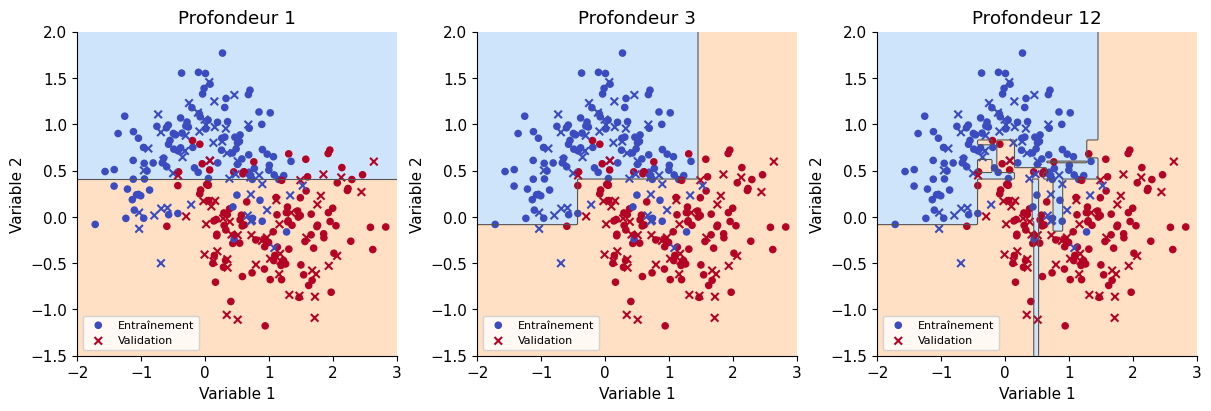

In [ ]:
# Plot the decision boundaries for three depths.
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, depth in zip(axes, [1, 3, 12]):
    draw_moon_boundary(ax, depth)
plt.show()


In [ ]:
# Explore the depth and show the training and validation scores.
def explore_depth(depth=4):
    fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    draw_moon_boundary(ax, depth)
    plt.show()
    frame = moon_frames[depth]
    print(f"Entraînement : {frame['train']:.1%} | validation : {frame['valid']:.1%}")

if SHOW_WIDGETS:
    depth_widget = widgets.interact(
        explore_depth,
        depth=widgets.IntSlider(value=3, min=1, max=12,
                                description="Profondeur", continuous_update=False),
    )


interactive(children=(IntSlider(value=3, continuous_update=False, description='Profondeur', max=12, min=1), Ou…

In [ ]:
# Reveal the scores; this output stays available without widgets.
for depth in [1, 3, 12]:
    frame = moon_frames[depth]
    print(f"Profondeur {depth:2d} | train {frame['train']:.1%} | validation {frame['valid']:.1%}")


Profondeur  1 | train 82.9% | validation 76.7%
Profondeur  3 | train 91.9% | validation 84.4%
Profondeur 12 | train 100.0% | validation 80.0%


## 5 · Choose with validation, not with the test set

Back to the digits. Two settings:

- `C`: **smaller = stronger regularization**, so more constrained coefficients;
- `k`: number of pixels kept.

`GridSearchCV` tries 16 configurations on **the same three folds**: 48 fits, then one refit of the best pipeline on all of `X_train`. The double underscore in `model__C` means "parameter C of the model step".

**Reminder:** optimal complexity on the same validation data — [lecture 3, slide 27](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a); regularization — slide 26. [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

**Question:** who chooses `C`: the classifier's `fit`, the validation grid, or the test set?


In [ ]:
# EXERCISE 4/5 · Define the settings and run the search on the training set.
# param_grid: model__C = [0.01, 0.1, 1, 10], pixels__k = [8, 16, 32, "all"].
# Create search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="accuracy",
#                              n_jobs=1, return_train_score=True), then search.fit.
param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "pixels__k": [8, 16, 32, "all"],
}
search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="accuracy",
                      n_jobs=1, return_train_score=True)
search.fit(X_train, y_train);


<details>
<summary>Solution to exercise 4 — open if needed</summary>

```python
# Compare the configurations on the three folds, without using the test set.
param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "pixels__k": [8, 16, 32, "all"],
}
search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="accuracy",
                      n_jobs=1, return_train_score=True)
search.fit(X_train, y_train);
```

</details>


In [ ]:
# Retrieve the search results; the best pipeline is already refit.
results = search.cv_results_
best_model = search.best_estimator_
print("Meilleurs réglages :", search.best_params_)
print(f"Meilleure accuracy CV moyenne : {search.best_score_:.1%}")


Meilleurs réglages : {'model__C': 1, 'pixels__k': 'all'}
Meilleure accuracy CV moyenne : 95.5%


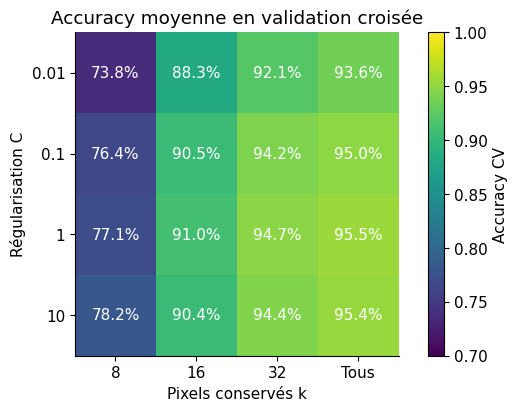

In [ ]:
# Arrange the grid: rows = C, columns = k; reuse its scores.
C_values = param_grid["model__C"]
pixel_choices = param_grid["pixels__k"]
shape = (len(C_values), len(pixel_choices))
score_map = results["mean_test_score"].reshape(shape)
train_map = results["mean_train_score"].reshape(shape)
std_map = results["std_test_score"].reshape(shape)

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
image = ax.imshow(score_map, cmap="viridis", vmin=0.7, vmax=1)
ax.set_xticks(range(len(pixel_choices)), labels=["8", "16", "32", "Tous"])
ax.set_yticks(range(len(C_values)), labels=C_values)
ax.set(xlabel="Pixels conservés k", ylabel="Régularisation C", title="Accuracy moyenne en validation croisée")
for row in range(len(C_values)):
    for column in range(len(pixel_choices)):
        ax.text(column, row, f"{score_map[row, column]:.1%}",
                ha="center", va="center", color="white")
fig.colorbar(image, ax=ax, label="Accuracy CV")
plt.show()


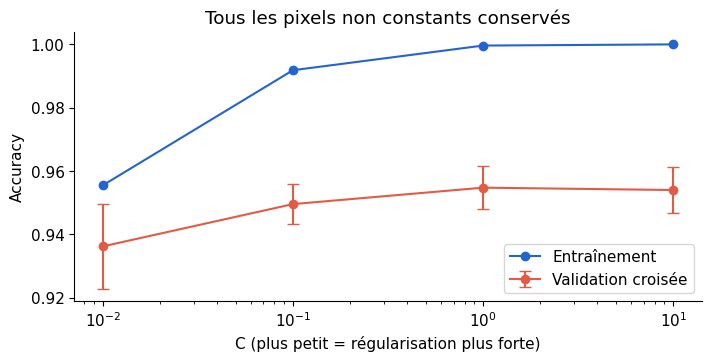

In [ ]:
# The last column is k="all"; the bars show the standard deviation across folds.
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.plot(C_values, train_map[:, -1], "o-", label="Entraînement", color="#2364ce")
ax.errorbar(C_values, score_map[:, -1], yerr=std_map[:, -1],
            fmt="o-", capsize=4, label="Validation croisée", color="#e25c45")
ax.set(xscale="log", xlabel="C (plus petit = régularisation plus forte)",
       ylabel="Accuracy", title="Tous les pixels non constants conservés")
ax.legend()
plt.show()


## 6 · Which pixels can we remove?

The orange pixels are **masked in the figure**, not replaced by zero in the data. The model only receives the kept columns.

The curve shows the best CV score for each `k`. To display the masks, we only need to fit `SelectKBest` on the training set: `C` does not change the selected pixels. No new classifier or test score is needed.

**Reminder:** removing features can simplify the model — [lecture 3, slide 26](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a). It does not automatically improve its score. [SelectKBest](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html).

**What do you think?** Which trade-off would you choose: 16 pixels, 32 pixels, or all of them? Look at the score gap too.


In [ ]:
# Refit only the selectors to display the pixels; reuse the CV results.
variable_mask = best_model.named_steps["variable_pixels"].get_support()
pixel_masks = {}
for k in pixel_choices:
    selector = SelectKBest(f_classif, k=k)
    selector.fit(X_train[:, variable_mask], y_train)
    # Place the mask of variable pixels back into the 64 positions of the image.
    mask = np.zeros(64, dtype=bool)
    mask[variable_mask] = selector.get_support()
    pixel_masks[k] = mask
pixel_cv_scores = score_map.max(axis=0)  # Best C for each column k.
pixel_example = X_train[y_train == 8][0].reshape(8, 8)


In [ ]:
# Show the kept pixels; NaN colors the others orange, without changing X.
pixel_cmap = plt.get_cmap("gray_r").copy()
pixel_cmap.set_bad("#f5bf62")

def draw_pixels(ax, mask, title):
    image = np.where(mask.reshape(8, 8), pixel_example, np.nan)
    ax.imshow(image, cmap=pixel_cmap, vmin=0, vmax=16)
    ax.set_title(title)
    ax.set_axis_off()


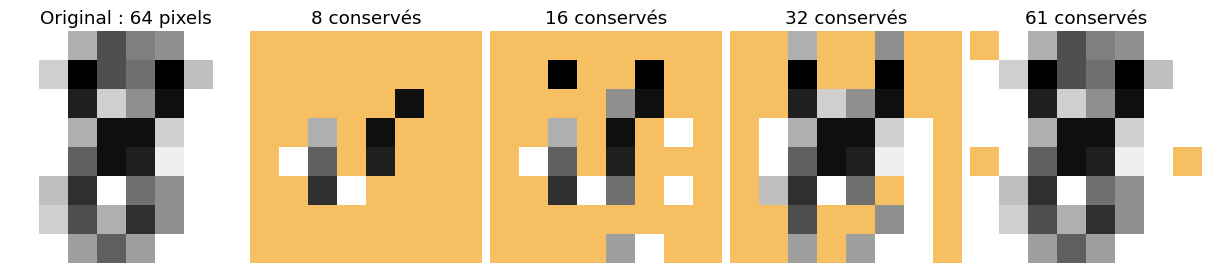

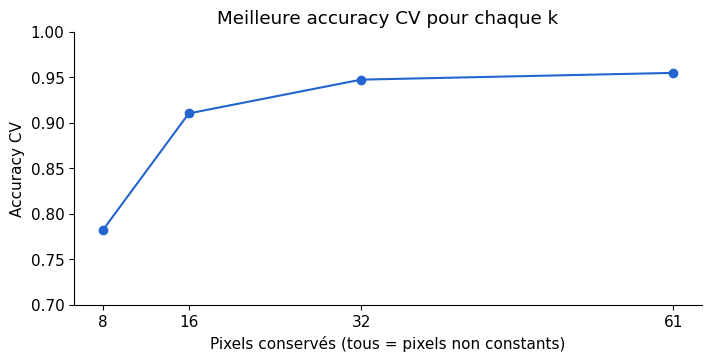

In [ ]:
# Compare the four masks and their best CV score, even without widgets.
fig, axes = plt.subplots(1, 5, figsize=(12, 3), layout="constrained")
draw_pixels(axes[0], np.ones(64, dtype=bool), "Original : 64 pixels")
for ax, k in zip(axes[1:], pixel_choices):
    draw_pixels(ax, pixel_masks[k], f"{pixel_masks[k].sum()} conservés")
plt.show()

counts = [pixel_masks[k].sum() for k in pixel_choices]
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.plot(counts, pixel_cv_scores, "o-", color="#2364ce")
ax.set_xticks(counts)
ax.set(xlabel="Pixels conservés (tous = pixels non constants)", ylabel="Accuracy CV",
       title="Meilleure accuracy CV pour chaque k")
ax.set_ylim(0.7, 1)
plt.show()


In [ ]:
# Move the slider to pick a precomputed mask and score.
def explore_pixels(k="all"):
    column = pixel_choices.index(k)
    fig, axes = plt.subplots(1, 2, figsize=(7, 3), layout="constrained")
    draw_pixels(axes[0], np.ones(64, dtype=bool), "Original")
    draw_pixels(axes[1], pixel_masks[k], f"{pixel_masks[k].sum()} conservés")
    fig.suptitle(f"Accuracy CV : {pixel_cv_scores[column]:.1%} | orange = supprimé")
    plt.show()

if SHOW_WIDGETS:
    pixel_widget = widgets.interact(
        explore_pixels,
        k=widgets.SelectionSlider(options=[("8", 8), ("16", 16), ("32", 32), ("Tous", "all")],
                                  value="all", description="Pixels", continuous_update=False),
    )


interactive(children=(SelectionSlider(continuous_update=False, description='Pixels', index=3, options=(('8', 8…

## 7 · Opening the test set: succeeding is not understanding everything

The pipeline and its settings are now fixed. **We open the test set for the final assessment, not to pick another C or k.**

Accuracy is the proportion of correctly predicted classes. The confusion matrix explains **where** the errors are; it is not a single metric. Rows = true classes, columns = predicted classes.

**Reminder:** diagnosis and confusion matrix — [lecture 4, slides 32 and 58](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a). [Confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html).

**Question:** if the model reports 94% for a digit, is it necessarily correct?


In [ ]:
# EXERCISE 5/5 · Predict the classes and their probabilities, and find the errors.
# Create prediction with best_model.predict(X_test).
# Create probabilities with best_model.predict_proba(X_test).
# Create errors by comparing prediction to y_test.
prediction = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)
errors = prediction != y_test


<details>
<summary>Solution to exercise 5 — open if needed</summary>

```python
# Predict without retraining; a boolean mask marks the wrong classes.
prediction = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)
errors = prediction != y_test
```

</details>


In [ ]:
# Evaluate once the model is fixed, then sort its errors by confidence.
test_accuracy = accuracy_score(y_test, prediction)
baseline_test_accuracy = baseline.score(X_test, y_test)
confidence = probabilities.max(axis=1)
classes = best_model.classes_

wrong_indices = np.flatnonzero(errors)  # Positions of the True values in the mask.
order = np.argsort(-confidence[wrong_indices])  # Decreasing confidence.
wrong_indices = wrong_indices[order]
print(f"Accuracy de test : {test_accuracy:.1%} | baseline : {baseline_test_accuracy:.1%}")
print("Erreurs :", errors.sum(), "/", len(y_test))


Accuracy de test : 97.8% | baseline : 10.2%
Erreurs : 10 / 450


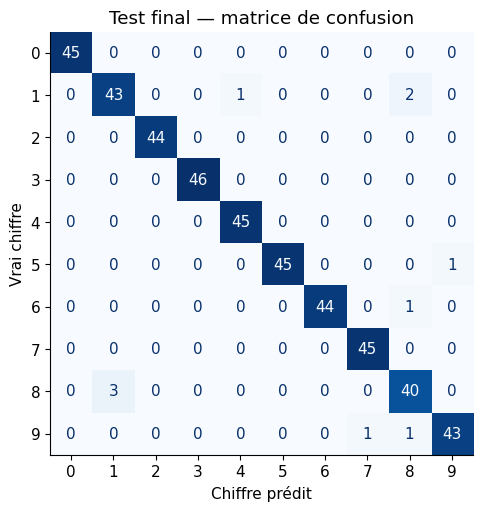

In [ ]:
# Read the matrix: the diagonal is correct, off-diagonal cells are errors.
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    y_test, prediction, labels=classes, display_labels=classes, ax=ax, cmap="Blues", colorbar=False
)
ax.set(xlabel="Chiffre prédit", ylabel="Vrai chiffre", title="Test final — matrice de confusion")
plt.show()


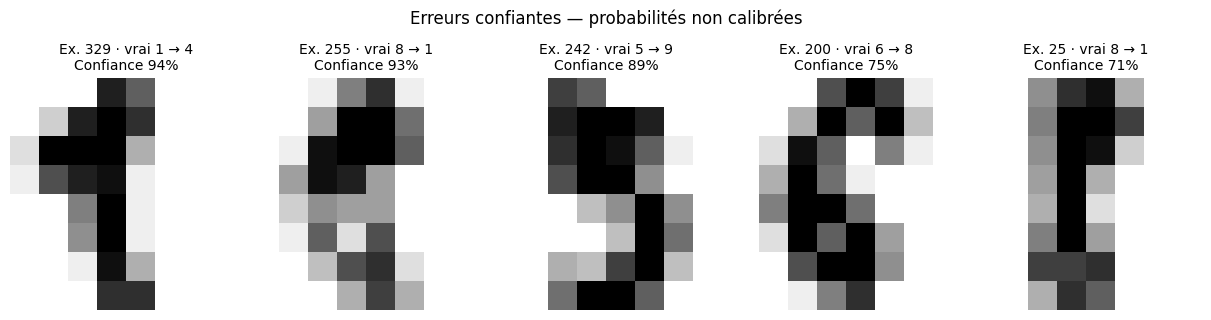

In [ ]:
# Show the most confident errors; note their index for the explorer below.
fig, axes = plt.subplots(1, 5, figsize=(12, 3.5), layout="constrained")
for ax in axes:
    ax.set_axis_off()
for ax, index in zip(axes, wrong_indices[:5]):
    ax.imshow(X_test[index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Ex. {index} · vrai {y_test[index]} → {prediction[index]}\nConfiance {confidence[index]:.0%}", fontsize=10)
fig.suptitle("Erreurs confiantes — probabilités non calibrées", fontsize=12)
plt.show()


In [ ]:
# Show the chosen test row and its ten precomputed probabilities.
def explore_prediction(index=0):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
    axes[0].imshow(X_test[index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    axes[0].set_title(f"Ex. {index} · vrai {y_test[index]} / prédit {prediction[index]}")
    axes[0].set_axis_off()
    colors = np.where(classes == prediction[index], "#e25c45", "#adc7e9")
    axes[1].bar(classes, probabilities[index], color=colors)
    axes[1].set(xticks=classes, ylim=(0, 1), xlabel="Chiffre", ylabel="Probabilité du modèle",
                title=f"Confiance {confidence[index]:.1%} — non calibrée")
    plt.show()


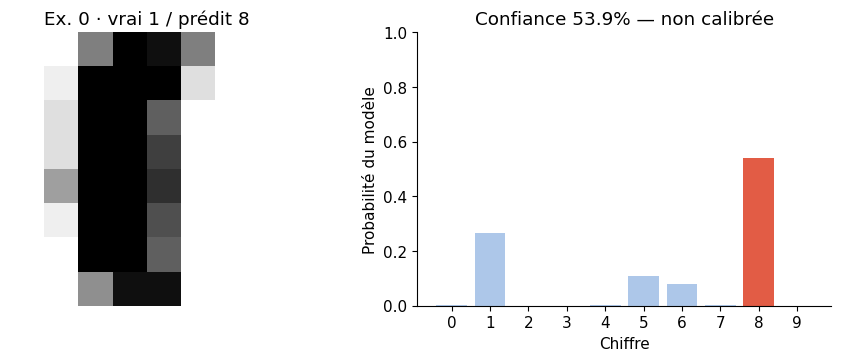

In [ ]:
# Show one example without a widget; replace 0 with an index from the gallery.
explore_prediction(0)


In [ ]:
# Choose the index of a test example with the slider.
if SHOW_WIDGETS:
    prediction_widget = widgets.interact(
        explore_prediction,
        index=widgets.IntSlider(value=0, min=0, max=len(X_test) - 1,
                                description="Indice", continuous_update=False),
    )


## 8 · This workflow comes back in the NHL project

The Digits demo does not replace the data or the deliverables required in the project. The cleaned table from **milestone 1** becomes the basis of the modeling workflow.

| Here | Possible transfer to the project |
|---|---|
| One digit / one row | One shot / one row of the cleaned table |
| Pixel intensities | Features available before the prediction: distance, angle… |
| Majority baseline | Simple reference; beware of rare goals |
| Pipeline and CV | Reproducible preprocessing, justified choice of settings |
| Held-out test set | A split suited to games and chronology |

**Reminder:** measuring the right metric and avoiding leakage — [lecture 7, slide 11](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a).

**Last question:** to predict goals on new games, why could randomly mixing the shots of the same game between train and validation be a problem?


## References

[IFT3700/6758 course, 2026](https://fracturedplane.notion.site/Cours-de-Science-des-Donn-es-IFT3700-6758A-2026-3c1214857276818499f7e8eee49dc68a). Reminders: lecture 3, slides 14, 24, 26–27; lecture 4, slides 8, 32, 58; lecture 7, slide 11.

Going further: [scikit-learn labs](https://github.com/Jay-D13/ift3700-6758/blob/ddb6cdbc6c344449c5610a7ad45766293ef2e943/solutions_ta/anciens_labs/sklearn/en/sklearn_2020_solution.ipynb) · [IFT6758 2020 validation](https://github.com/Jay-D13/ift3700-6758/blob/ddb6cdbc6c344449c5610a7ad45766293ef2e943/solutions_ta/anciens_labs/validation/en/validation_pca_clustering_2020_solution.ipynb).

Documentation: [Digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html) · [Pipelines and leakage](https://scikit-learn.org/stable/common_pitfalls.html) · [CV](https://scikit-learn.org/stable/modules/cross_validation.html) · [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) · [Feature selection](https://scikit-learn.org/stable/modules/feature_selection.html) · [uv and Jupyter](https://docs.astral.sh/uv/guides/integration/jupyter/).
